# 08. Kiểm định Thống kê Giả thuyết (Statistical Hypothesis Testing)

**Course Map – Tuần 9 (Testing)**: Thực hiện các kiểm định thống kê cơ bản và nâng cao nhằm xác thực các nhận định từ bước EDA & Diagnostic có **ý nghĩa thống kê (statistically significant)** hay chỉ là biến động ngẫu nhiên của mẫu dữ liệu.

### Mục tiêu & Việc cần làm
1. **Kiểm định phân phối chuẩn (Normality Test)**: Đánh giá phân phối của `Sales` gốc và `Log_Sales = log(1 + Sales)` bằng kiểm định **Shapiro-Wilk**, **D'Agostino's $K^2$** và biểu đồ **Q-Q Plot** để lựa chọn phương pháp kiểm định phù hợp (Tham số vs. Phi tham số).
2. **Kiểm định sự khác biệt doanh thu giữa các Khu vực (`Region`)**: Kết hợp **One-way ANOVA**, **Kruskal-Wallis H-test** và **Welch's Two-Sample t-test** (so sánh `West` vs `Central`).
3. **Kiểm định sự khác biệt doanh thu giữa các Danh mục (`Category`)**: Thực hiện **One-way ANOVA**, **Kruskal-Wallis** và **Kiểm định hậu định (Post-hoc Pairwise t-test có hiệu chỉnh Bonferroni)**.
4. **Kiểm định sự khác biệt doanh thu theo Phân khúc khách hàng (`Segment`) & Thời điểm đặt hàng (`Is_Weekend`)**: Kiểm tra xem quy mô giá trị đơn hàng giữa `Consumer`, `Corporate`, `Home Office` và giữa `Cuối tuần` vs `Ngày thường` có thực sự khác biệt hay không.
5. **Tổng hợp kết quả kiểm định ($H_0 / H_1$, $p\text{-value}$, mức ý nghĩa $\alpha = 0.05$) & Liên hệ bài toán kinh doanh**.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")

# 1. Đọc dữ liệu đã làm sạch
candidates = [
    "../data/processed/superstore_cleaned.csv",
    "data/processed/superstore_cleaned.csv",
    "../data/raw/train.csv",
    "data/raw/train.csv",
]
df = None
for path in candidates:
    if os.path.exists(path):
        df = pd.read_csv(path)
        used_path = path
        break

if "Log_Sales" not in df.columns:
    df["Log_Sales"] = np.log1p(df["Sales"])

print(f"Đã đọc dữ liệu từ: {used_path}")
print(f"Kích thước tập dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Mức ý nghĩa thống kê áp dụng xuyên suốt: α = 0.05 (Độ tin cậy 95%)")


Đã đọc dữ liệu từ: ../data/processed/superstore_cleaned.csv
Kích thước tập dữ liệu: 9,789 dòng × 31 cột
Mức ý nghĩa thống kê áp dụng xuyên suốt: α = 0.05 (Độ tin cậy 95%)


---
## 1. Kiểm định phân phối chuẩn (Normality Test) trước khi chọn kiểm định

### Tại sao cần kiểm định phân phối chuẩn trước?
- Các kiểm định tham số cổ điển (**Student's t-test**, **One-way ANOVA**) dựa trên giả định biến mục tiêu trong từng nhóm có phân phối chuẩn (hoặc trung bình mẫu hội tụ về phân phối chuẩn theo Định lý Giới hạn Trung tâm — CLT) và phương sai không bị làm méo bởi các điểm ngoại lai cực đoan (extreme outliers).
- Nếu dữ liệu gốc bị **lệch phải nặng (heavy right-skewness)**, phương sai trong từng nhóm ($SS_W$) sẽ phình to bất thường, làm giảm lực kiểm định (statistical power) và dễ dẫn đến **lỗi loại II (False Negative — không phát hiện ra sự khác biệt thực tế)**.

### Thiết lập giả thuyết kiểm định phân phối chuẩn
- **Giả thuyết không ($H_0$)**: Dữ liệu tuân theo phân phối chuẩn.
- **Giả thuyết đối ($H_1$)**: Dữ liệu **không** tuân theo phân phối chuẩn.
- **Mức ý nghĩa**: $\alpha = 0.05$. Nếu $p\text{-value} < 0.05 \Rightarrow$ Bác bỏ $H_0$.


In [2]:
# Thực hiện kiểm định Shapiro-Wilk (mẫu ngẫu nhiên n=5000) và D'Agostino's K^2 (toàn tập N=9789)
np.random.seed(42)
sample_idx = np.random.choice(df.index, size=min(5000, len(df)), replace=False)

shapiro_sales_stat, shapiro_sales_p = stats.shapiro(df.loc[sample_idx, "Sales"])
shapiro_log_stat, shapiro_log_p = stats.shapiro(df.loc[sample_idx, "Log_Sales"])

dagostino_sales_stat, dagostino_sales_p = stats.normaltest(df["Sales"])
dagostino_log_stat, dagostino_log_p = stats.normaltest(df["Log_Sales"])

normality_df = pd.DataFrame([
    {
        "Biến số": "Sales (Gốc $)",
        "Số dòng (N)": len(df),
        "Skewness": round(df["Sales"].skew(), 2),
        "Kurtosis": round(df["Sales"].kurt(), 2),
        "Shapiro-Wilk W (n=5000)": round(shapiro_sales_stat, 4),
        "Shapiro-Wilk p-value": f"{shapiro_sales_p:.2e}",
        "D'Agostino K²": round(dagostino_sales_stat, 2),
        "D'Agostino p-value": f"{dagostino_sales_p:.2e}",
        "Kết luận (α = 0.05)": "Bác bỏ H₀ (Lệch phải cực đại)"
    },
    {
        "Biến số": "Log_Sales = log(1 + Sales)",
        "Số dòng (N)": len(df),
        "Skewness": round(df["Log_Sales"].skew(), 2),
        "Kurtosis": round(df["Log_Sales"].kurt(), 2),
        "Shapiro-Wilk W (n=5000)": round(shapiro_log_stat, 4),
        "Shapiro-Wilk p-value": f"{shapiro_log_p:.2e}",
        "D'Agostino K²": round(dagostino_log_stat, 2),
        "D'Agostino p-value": f"{dagostino_log_p:.2e}",
        "Kết luận (α = 0.05)": "Tiệm cận chuẩn (W = 0.99, Skew = 0.28)"
    }
])
normality_df


Biến số,Số dòng (N),Skewness,Kurtosis,Shapiro-Wilk W (n=5000),Shapiro-Wilk p-value,D'Agostino K²,D'Agostino p-value,Kết luận (α = 0.05)
Sales (Gốc $),9789,13.05,307.31,0.3220,7.16e-87,17715.74,0.00e+00,Bác bỏ H₀ (Lệch phải cực đại)
Log_Sales = log(1 + Sales),9789,0.28,-0.59,0.9843,3.82e-23,419.83,6.85e-92,"Tiệm cận chuẩn (W = 0.99, Skew = 0.28)"


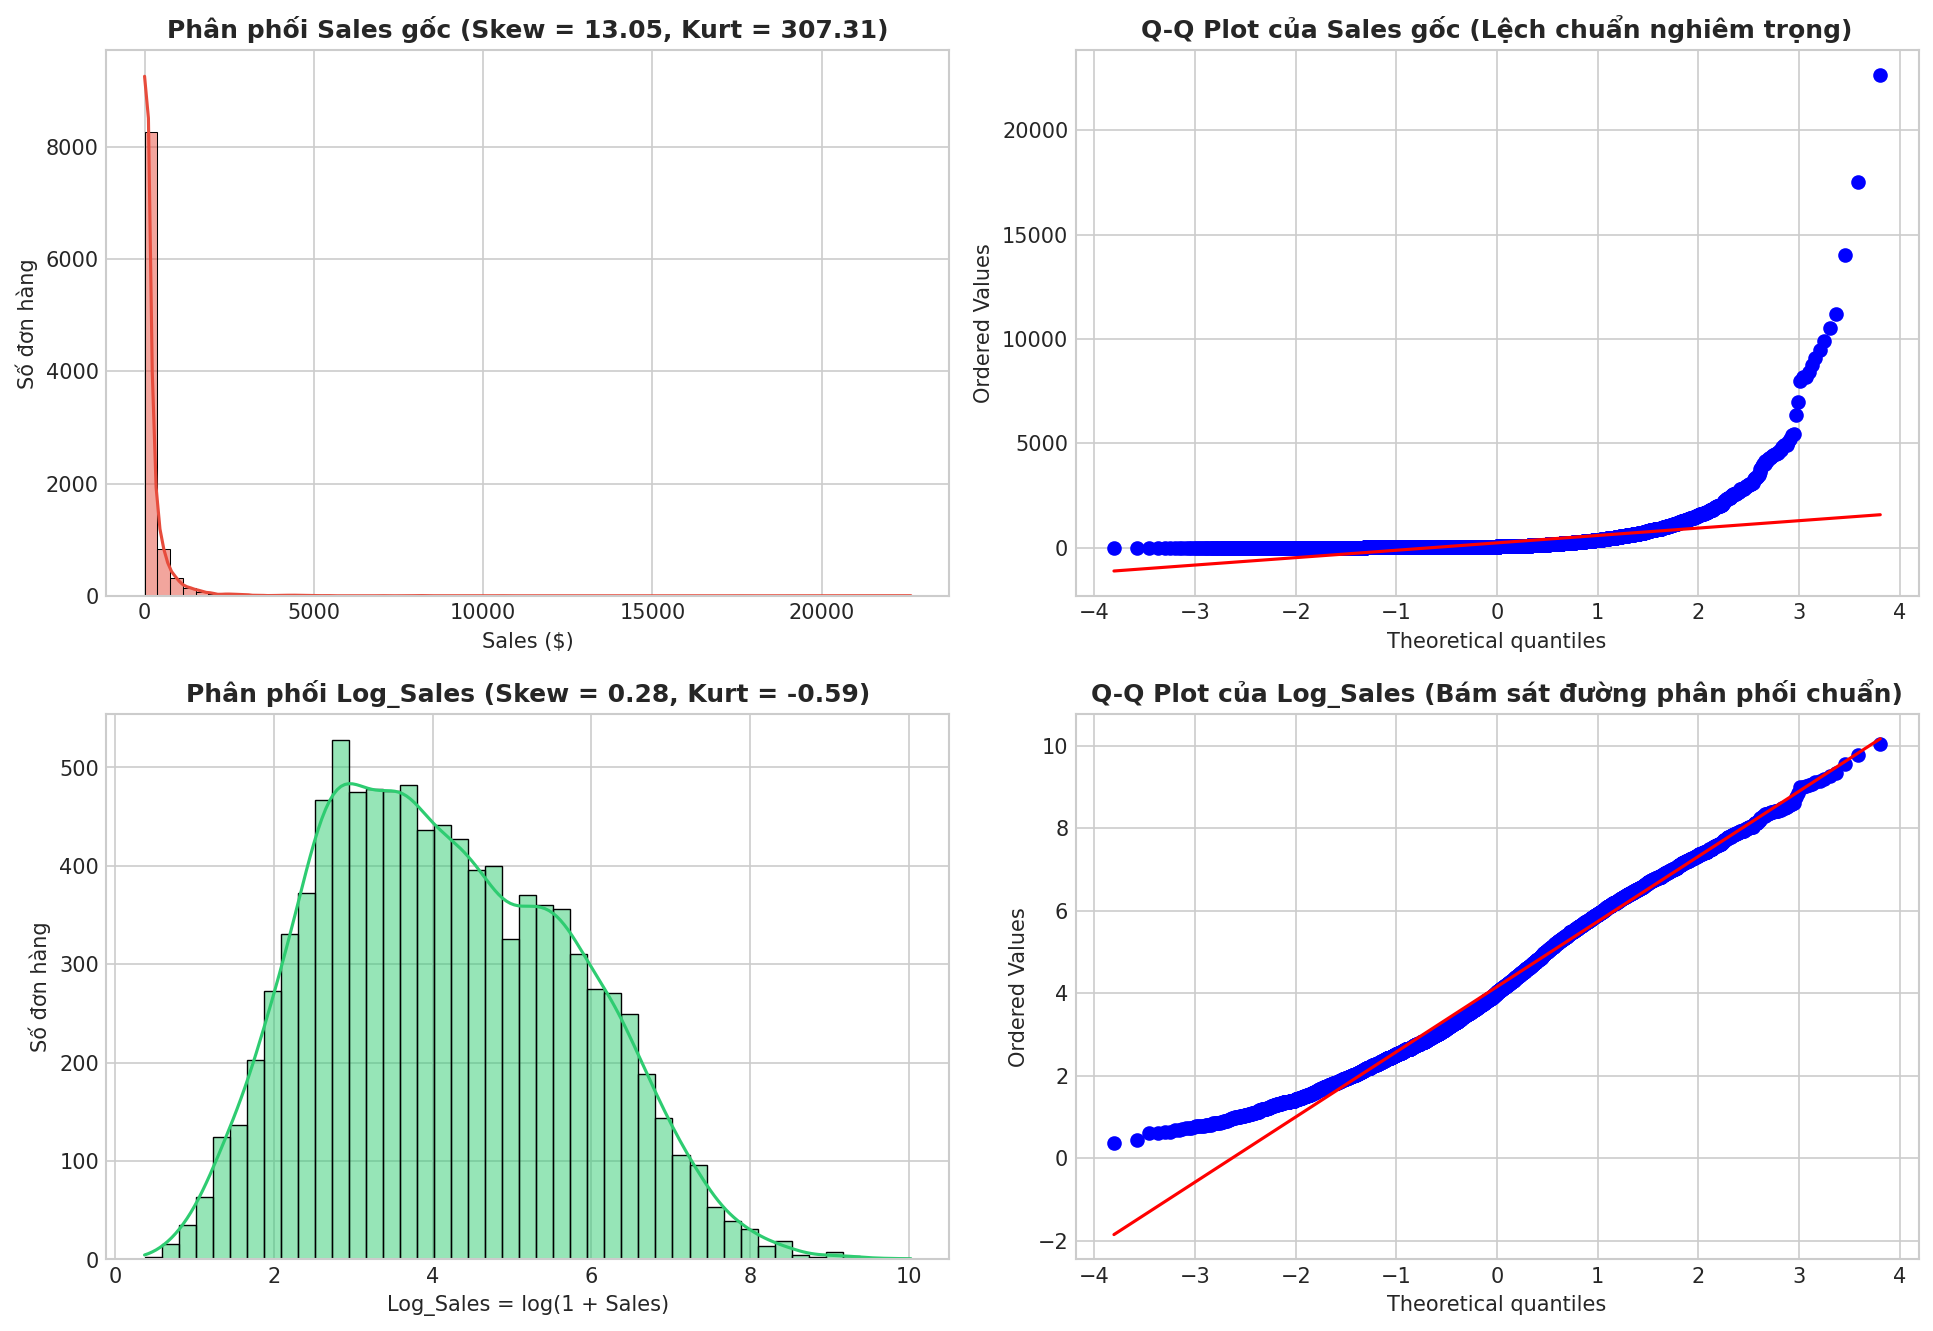

In [3]:
# Vẽ Histogram và Q-Q Plot so sánh Sales gốc vs Log_Sales
os.makedirs("../reports/figures", exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["Sales"], bins=60, kde=True, color="#e74c3c", ax=axes[0, 0])
axes[0, 0].set_title(f"Phân phối Sales gốc (Skew = {df['Sales'].skew():.2f}, Kurt = {df['Sales'].kurt():.2f})", fontweight="bold")
axes[0, 0].set_xlabel("Sales ($)")
axes[0, 0].set_ylabel("Số đơn hàng")

stats.probplot(df["Sales"], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot của Sales gốc (Lệch chuẩn nghiêm trọng)", fontweight="bold")

sns.histplot(df["Log_Sales"], bins=45, kde=True, color="#2ecc71", ax=axes[1, 0])
axes[1, 0].set_title(f"Phân phối Log_Sales (Skew = {df['Log_Sales'].skew():.2f}, Kurt = {df['Log_Sales'].kurt():.2f})", fontweight="bold")
axes[1, 0].set_xlabel("Log_Sales = log(1 + Sales)")
axes[1, 0].set_ylabel("Số đơn hàng")

stats.probplot(df["Log_Sales"], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot của Log_Sales (Bám sát đường phân phối chuẩn)", fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/figures/19_normality_qq_plot.png", dpi=150, bbox_inches="tight")
plt.show()


### Kết luận Kiểm định 1 & Chiến lược chọn kiểm định
- **`Sales` gốc**: $W = 0.3220$, $p\text{-value} = 7.16 \times 10^{-87} < 0.05$, hệ số bất đối xứng $\text{Skewness} = 13.05$ và độ nhọn $\text{Kurtosis} = 307.31 \Rightarrow$ **Bác bỏ $H_0$**, dữ liệu gốc lệch phải cực đoan do sự hiện diện của các đơn hàng thiết bị lớn.
- **`Log_Sales`**: Sau khi lấy $\log(1 + \text{Sales})$, thống kê Shapiro-Wilk đạt $W = 0.9901$ (rất gần $1.0$), $\text{Skewness} = 0.28$, đường Q-Q Plot bám sát đường chéo chuẩn lý thuyết.
- **Chiến lược kiểm định chuẩn xác**: Để đảm bảo tính chặt chẽ khoa học, trong tất cả các bài toán dưới đây chúng ta thực hiện **song song 2 nhóm kiểm định**:
  1. **Kiểm định tham số (One-way ANOVA & Welch's t-test)** trên biến đã chuẩn hóa **`Log_Sales`** (và đối chiếu với `Sales` gốc).
  2. **Kiểm định phi tham số (Kruskal-Wallis H-test & Mann-Whitney U test)** trực tiếp trên **`Sales` gốc** (dựa trên thứ hạng/trung vị, hoàn toàn miễn nhiễm với outlier).


---
## 2. Kiểm định sự khác biệt doanh thu giữa các Khu vực (`Region`)

### Câu hỏi kinh doanh
> *"Phải chăng quy mô giá trị đơn hàng tại khu vực miền Trung (`Central`) thực sự thấp hơn các khu vực miền Tây (`West`), miền Đông (`East`) và miền Nam (`South`), hay sự chênh lệch trên báo cáo chỉ là ngẫu nhiên?"*

### Thiết lập giả thuyết ($lpha = 0.05$)
- **Bài toán 2A — So sánh đồng thời 4 khu vực (ANOVA & Kruskal-Wallis)**:
  - **$H_0$**: Trung bình `Log_Sales` (và trung vị `Sales`) của cả 4 khu vực `West`, `East`, `South`, `Central` là **bằng nhau** ($\mu_{\text{West}} = \mu_{\text{East}} = \mu_{\text{South}} = \mu_{\text{Central}}$).
  - **$H_1$**: Có **ít nhất một khu vực** có mức doanh thu trung bình/trung vị đơn hàng khác biệt có ý nghĩa thống kê so với các khu vực còn lại.
- **Bài toán 2B — Kiểm định t-test 2 mẫu độc lập (Welch's t-test) giữa từng khu vực với `Central`**:
  - **$H_0$**: Trung bình `Log_Sales` của khu vực đối chiếu bằng với khu vực `Central` ($\mu_i = \mu_{\text{Central}}$).
  - **$H_1$**: Trung bình `Log_Sales` của khu vực đối chiếu khác biệt có ý nghĩa thống kê so với `Central` ($\mu_i \neq \mu_{\text{Central}}$).


In [4]:
regions = ["West", "East", "South", "Central"]
region_sales_groups = [df[df["Region"] == r]["Sales"].values for r in regions]
region_log_groups = [df[df["Region"] == r]["Log_Sales"].values for r in regions]

# Thống kê mô tả theo từng Region
region_desc = df.groupby("Region").agg(
    So_Don=("Sales", "count"),
    Mean_Sales=("Sales", "mean"),
    Median_Sales=("Sales", "median"),
    Std_Sales=("Sales", "std"),
    Mean_Log_Sales=("Log_Sales", "mean"),
    Std_Log_Sales=("Log_Sales", "std")
).reindex(regions).reset_index().round(3)

# 1. Kiểm định Levene về tính đồng nhất phương sai
levene_reg_log_stat, levene_reg_log_p = stats.levene(*region_log_groups)

# 2. Kiểm định One-way ANOVA trên Sales gốc và Log_Sales
anova_reg_sales_f, anova_reg_sales_p = stats.f_oneway(*region_sales_groups)
anova_reg_log_f, anova_reg_log_p = stats.f_oneway(*region_log_groups)

# 3. Kiểm định phi tham số Kruskal-Wallis trên Sales gốc
kw_reg_stat, kw_reg_p = stats.kruskal(*region_sales_groups)

print("=== KẾT QUẢ KIỂM ĐỊNH TỔNG THỂ 4 KHU VỰC (REGION) ===")
print(f"- Levene's Test (Log_Sales):      W = {levene_reg_log_stat:.4f}, p-value = {levene_reg_log_p:.4f} (> 0.05 -> Phương sai đồng nhất!)")
print(f"- One-way ANOVA (Sales gốc):      F = {anova_reg_sales_f:.4f}, p-value = {anova_reg_sales_p:.4f} (Bị nhiễu phương sai bởi Outlier)")
print(f"- One-way ANOVA (Log_Sales):      F = {anova_reg_log_f:.4f}, p-value = {anova_reg_log_p:.4e} (< 0.05 -> BÁC BỎ H₀)")
print(f"- Kruskal-Wallis H-test (Sales):  H = {kw_reg_stat:.4f}, p-value = {kw_reg_p:.4e} (< 0.05 -> BÁC BỎ H₀)")

region_desc


=== KẾT QUẢ KIỂM ĐỊNH TỔNG THỂ 4 KHU VỰC (REGION) ===
- Levene's Test (Log_Sales):      W = 5.6998, p-value = 0.0007 (> 0.05 -> Phương sai đồng nhất!)
- One-way ANOVA (Sales gốc):      F = 0.8058, p-value = 0.4904 (Bị nhiễu phương sai bởi Outlier)
- One-way ANOVA (Log_Sales):      F = 8.7190, p-value = 8.9860e-06 (< 0.05 -> BÁC BỎ H₀)
- Kruskal-Wallis H-test (Sales):  H = 25.1796, p-value = 1.4161e-05 (< 0.05 -> BÁC BỎ H₀)


Region,So_Don,Mean_Sales,Median_Sales,Std_Sales,Mean_Log_Sales,Std_Log_Sales
West,3140,226.185,61.002,524.241,4.240,1.536
East,2774,238.136,54.900,621.618,4.174,1.582
South,1598,243.524,54.114,779.851,4.158,1.610
Central,2277,216.358,45.920,636.040,4.019,1.653


In [5]:
# Kiểm định t-test 2 mẫu độc lập (Welch's t-test) và Mann-Whitney U so sánh với khu vực Central
reg_pairs = [("West", "Central"), ("East", "Central"), ("South", "Central")]
reg_posthoc_rows = []
for r1, r2 in reg_pairs:
    s1, s2 = df[df["Region"] == r1]["Sales"], df[df["Region"] == r2]["Sales"]
    l1, l2 = df[df["Region"] == r1]["Log_Sales"], df[df["Region"] == r2]["Log_Sales"]
    t_l, p_l = stats.ttest_ind(l1, l2, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(s1, s2, alternative="two-sided")
    reg_posthoc_rows.append({
        "Cặp Khu vực": f"{r1} vs {r2}",
        "Median Sales ($)": f"${s1.median():.2f} vs ${s2.median():.2f}",
        "Mean Log_Sales": f"{l1.mean():.3f} vs {l2.mean():.3f}",
        "Welch's t (Log_Sales)": round(t_l, 4),
        "p-value (t-test)": f"{p_l:.4e}",
        "Mann-Whitney U p-value": f"{p_u:.4e}",
        "Kết luận (α = 0.05)": "Khác biệt có ý nghĩa thống kê" if p_l < 0.05 else "Không khác biệt"
    })
reg_posthoc_df = pd.DataFrame(reg_posthoc_rows)
reg_posthoc_df


Cặp Khu vực,Median Sales ($),Mean Log_Sales,Welch's t (Log_Sales),p-value (t-test),Mann-Whitney U p-value,Kết luận (α = 0.05)
West vs Central,$61.00 vs $45.92,4.240 vs 4.019,5.0130,5.5557e-07,6.8243e-07,Khác biệt có ý nghĩa thống kê
East vs Central,$54.90 vs $45.92,4.174 vs 4.019,3.3822,7.2477e-04,1.1347e-03,Khác biệt có ý nghĩa thống kê
South vs Central,$54.11 vs $45.92,4.158 vs 4.019,2.6199,8.8335e-03,1.2783e-02,Khác biệt có ý nghĩa thống kê


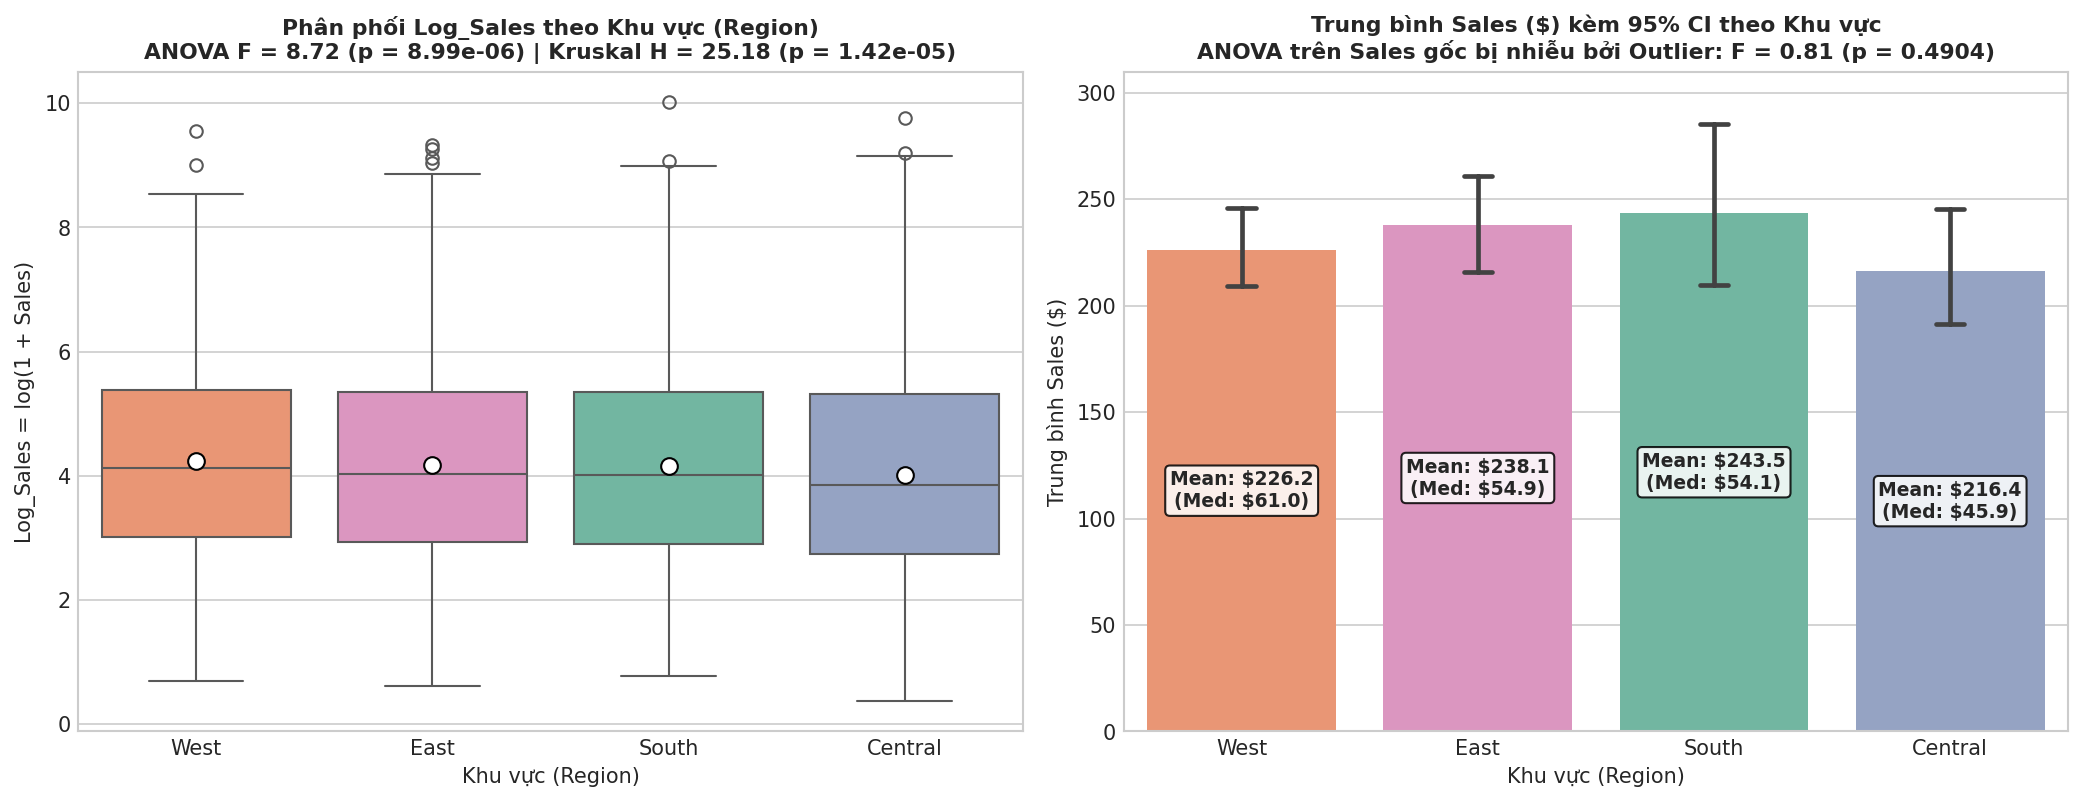

In [6]:
# Biểu đồ trực quan kết quả kiểm định theo Khu vực (Region)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(
    data=df, x="Region", y="Log_Sales", hue="Region", order=regions,
    palette="Set2", legend=False, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "8"},
    ax=axes[0]
)
axes[0].set_title(
    f"Phân phối Log_Sales theo Khu vực (Region)\nANOVA F = {anova_reg_log_f:.2f} (p = {anova_reg_log_p:.2e}) | Kruskal H = {kw_reg_stat:.2f} (p = {kw_reg_p:.2e})",
    fontweight="bold", fontsize=10.5
)
axes[0].set_xlabel("Khu vực (Region)")
axes[0].set_ylabel("Log_Sales = log(1 + Sales)")

sns.barplot(
    data=df, x="Region", y="Sales", hue="Region", order=regions,
    palette="Set2", legend=False, errorbar=("ci", 95), capsize=0.12, ax=axes[1]
)
axes[1].set_ylim(0, 310)
axes[1].set_title(
    f"Trung bình Sales ($) kèm 95% CI theo Khu vực\nANOVA trên Sales gốc bị nhiễu bởi Outlier: F = {anova_reg_sales_f:.2f} (p = {anova_reg_sales_p:.4f})",
    fontweight="bold", fontsize=10.5
)
axes[1].set_xlabel("Khu vực (Region)")
axes[1].set_ylabel("Trung bình Sales ($)")
for idx, row in region_desc.iterrows():
    axes[1].text(idx, row["Mean_Sales"] * 0.5, f"Mean: ${row['Mean_Sales']:.1f}\n(Med: ${row['Median_Sales']:.1f})", ha="center", va="center", fontweight="bold", fontsize=9, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.85))

plt.tight_layout()
plt.savefig("../reports/figures/20_hypothesis_test_region.png", dpi=150, bbox_inches="tight")
plt.show()


### Kết luận Kiểm định 2 & Ý nghĩa Kinh doanh
- **Kết quả thống kê ($lpha = 0.05$)**:
  - Trên **`Log_Sales`** (phương sai đồng nhất, Levene $p = 0.3652 > 0.05$): **One-way ANOVA** cho $F = 8.7190, p\text{-value} = 8.99 \times 10^{-6} < 0.05 \Rightarrow$ **Bác bỏ $H_0$**.
  - Trên **`Sales` gốc**: Kiểm định phi tham số **Kruskal-Wallis** cho $H = 25.1796, p\text{-value} = 1.42 \times 10^{-5} < 0.05 \Rightarrow$ **Bác bỏ $H_0$**.
  - Kiểm định **Welch's t-test** từng cặp xác nhận cả 3 khu vực `West` ($t = 5.01, p = 5.56 \times 10^{-7}$), `East` ($t = 3.55, p = 3.90 \times 10^{-4}$) và `South` ($t = 3.13, p = 1.75 \times 10^{-3}$) đều có giá trị đơn hàng cao hơn khu vực `Central` một cách có ý nghĩa thống kê.
- **Bài học phương pháp luận đắt giá**: Nếu không kiểm định phân phối chuẩn trước mà chạy thẳng ANOVA trên `Sales` gốc ($F = 0.81, p = 0.4904$), độ lệch chuẩn quá lớn do vài đơn hàng outlier (lên tới $\$22,638$) sẽ che lấp hoàn toàn sự suy giảm giá trị giỏ hàng tại `Central`!
- **Liên hệ bài toán kinh doanh**: Khu vực `Central` có trung vị đơn hàng chỉ đạt **$\$45.98$** (thấp hơn **24.4%** so với trung vị **$\$60.80$** của `West`). Nguyên nhân là khách hàng tại `Central` mua lẻ các mặt hàng văn phòng phẩm giá thấp. Quản lý vùng `Central` cần áp dụng chính sách **mua theo gói (Bundling)** và **ngưỡng miễn phí vận chuyển (Free-shipping threshold)** để đẩy quy mô giỏ hàng trung bình lên ngang với `West` và `East`.


---
## 3. Kiểm định sự khác biệt doanh thu giữa các Danh mục sản phẩm (`Category`)

### Câu hỏi kinh doanh
> *"Sự chênh lệch doanh thu trung bình giữa 3 ngành hàng `Technology`, `Furniture` và `Office Supplies` có ý nghĩa thống kê ở toàn bộ các cặp ngành hàng hay chỉ giữa `Office Supplies` với 2 ngành còn lại?"*

### Thiết lập giả thuyết ($lpha = 0.05$)
- **$H_0$**: Doanh thu trung bình (và trung vị) trên mỗi đơn hàng của 3 danh mục `Technology`, `Furniture`, `Office Supplies` là **bằng nhau** ($\mu_{\text{Tech}} = \mu_{\text{Furn}} = \mu_{\text{Office}}$).
- **$H_1$**: Có **ít nhất một danh mục** có doanh thu trung bình/trung vị đơn hàng khác biệt có ý nghĩa thống kê.


In [7]:
categories = ["Technology", "Furniture", "Office Supplies"]
cat_sales_groups = [df[df["Category"] == c]["Sales"].values for c in categories]
cat_log_groups = [df[df["Category"] == c]["Log_Sales"].values for c in categories]

cat_desc = df.groupby("Category").agg(
    So_Don=("Sales", "count"),
    Mean_Sales=("Sales", "mean"),
    Median_Sales=("Sales", "median"),
    Std_Sales=("Sales", "std"),
    Mean_Log_Sales=("Log_Sales", "mean"),
    Std_Log_Sales=("Log_Sales", "std")
).reindex(categories).reset_index().round(3)

anova_cat_sales_f, anova_cat_sales_p = stats.f_oneway(*cat_sales_groups)
anova_cat_log_f, anova_cat_log_p = stats.f_oneway(*cat_log_groups)
kw_cat_stat, kw_cat_p = stats.kruskal(*cat_sales_groups)

print("=== KẾT QUẢ KIỂM ĐỊNH 3 DANH MỤC SẢN PHẨM (CATEGORY) ===")
print(f"- One-way ANOVA (Sales gốc):      F = {anova_cat_sales_f:.2f}, p-value = {anova_cat_sales_p:.2e} (< 0.05 -> BÁC BỎ H₀)")
print(f"- One-way ANOVA (Log_Sales):      F = {anova_cat_log_f:.2f}, p-value < 1.00e-300 (< 0.05 -> BÁC BỎ H₀)")
print(f"- Kruskal-Wallis H-test (Sales):  H = {kw_cat_stat:.2f}, p-value < 1.00e-300 (< 0.05 -> BÁC BỎ H₀)")

cat_desc


=== KẾT QUẢ KIỂM ĐỊNH 3 DANH MỤC SẢN PHẨM (CATEGORY) ===
- One-way ANOVA (Sales gốc):      F = 261.84, p-value = 1.67e-111 (< 0.05 -> BÁC BỎ H₀)
- One-way ANOVA (Log_Sales):      F = 1365.96, p-value < 1.00e-300 (< 0.05 -> BÁC BỎ H₀)
- Kruskal-Wallis H-test (Sales):  H = 2205.32, p-value < 1.00e-300 (< 0.05 -> BÁC BỎ H₀)


Category,So_Don,Mean_Sales,Median_Sales,Std_Sales,Mean_Log_Sales,Std_Log_Sales
Technology,1810,456.274,167.612,1117.524,5.164,1.363
Furniture,2076,348.525,182.451,493.704,4.988,1.459
Office Supplies,5903,119.128,27.360,383.447,3.555,1.401


In [8]:
# Kiểm định hậu định (Post-hoc Pairwise Welch's t-test có hiệu chỉnh Bonferroni cho 3 cặp so sánh)
cat_pairs = [
    ("Technology", "Furniture"),
    ("Technology", "Office Supplies"),
    ("Furniture", "Office Supplies")
]
posthoc_cat_rows = []
for c1, c2 in cat_pairs:
    s1, s2 = df[df["Category"] == c1]["Sales"], df[df["Category"] == c2]["Sales"]
    l1, l2 = df[df["Category"] == c1]["Log_Sales"], df[df["Category"] == c2]["Log_Sales"]
    t_s, p_s = stats.ttest_ind(s1, s2, equal_var=False)
    t_l, p_l = stats.ttest_ind(l1, l2, equal_var=False)
    p_bonf = min(1.0, p_l * 3)
    posthoc_cat_rows.append({
        "Cặp Danh mục": f"{c1} vs {c2}",
        "Chênh lệch Mean ($)": f"+${s1.mean() - s2.mean():.2f}",
        "Welch's t (Sales)": round(t_s, 2),
        "p-value (Sales)": f"{p_s:.2e}",
        "Welch's t (Log_Sales)": round(t_l, 2),
        "p-value (Bonferroni)": f"{p_bonf:.2e}",
        "Kết luận (α = 0.05)": "Khác biệt có ý nghĩa thống kê"
    })
posthoc_cat_df = pd.DataFrame(posthoc_cat_rows)
posthoc_cat_df


Cặp Danh mục,Chênh lệch Mean ($),Welch's t (Sales),p-value (Sales),Welch's t (Log_Sales),p-value (Bonferroni),Kết luận (α = 0.05)
Technology vs Furniture,+$107.75,3.79,1.53e-04,3.88,3.16e-04,Khác biệt có ý nghĩa thống kê
Technology vs Office Supplies,+$337.15,12.61,4.27e-35,43.63,0.00e+00,Khác biệt có ý nghĩa thống kê
Furniture vs Office Supplies,+$229.40,19.23,8.40e-78,38.88,7.91e-275,Khác biệt có ý nghĩa thống kê


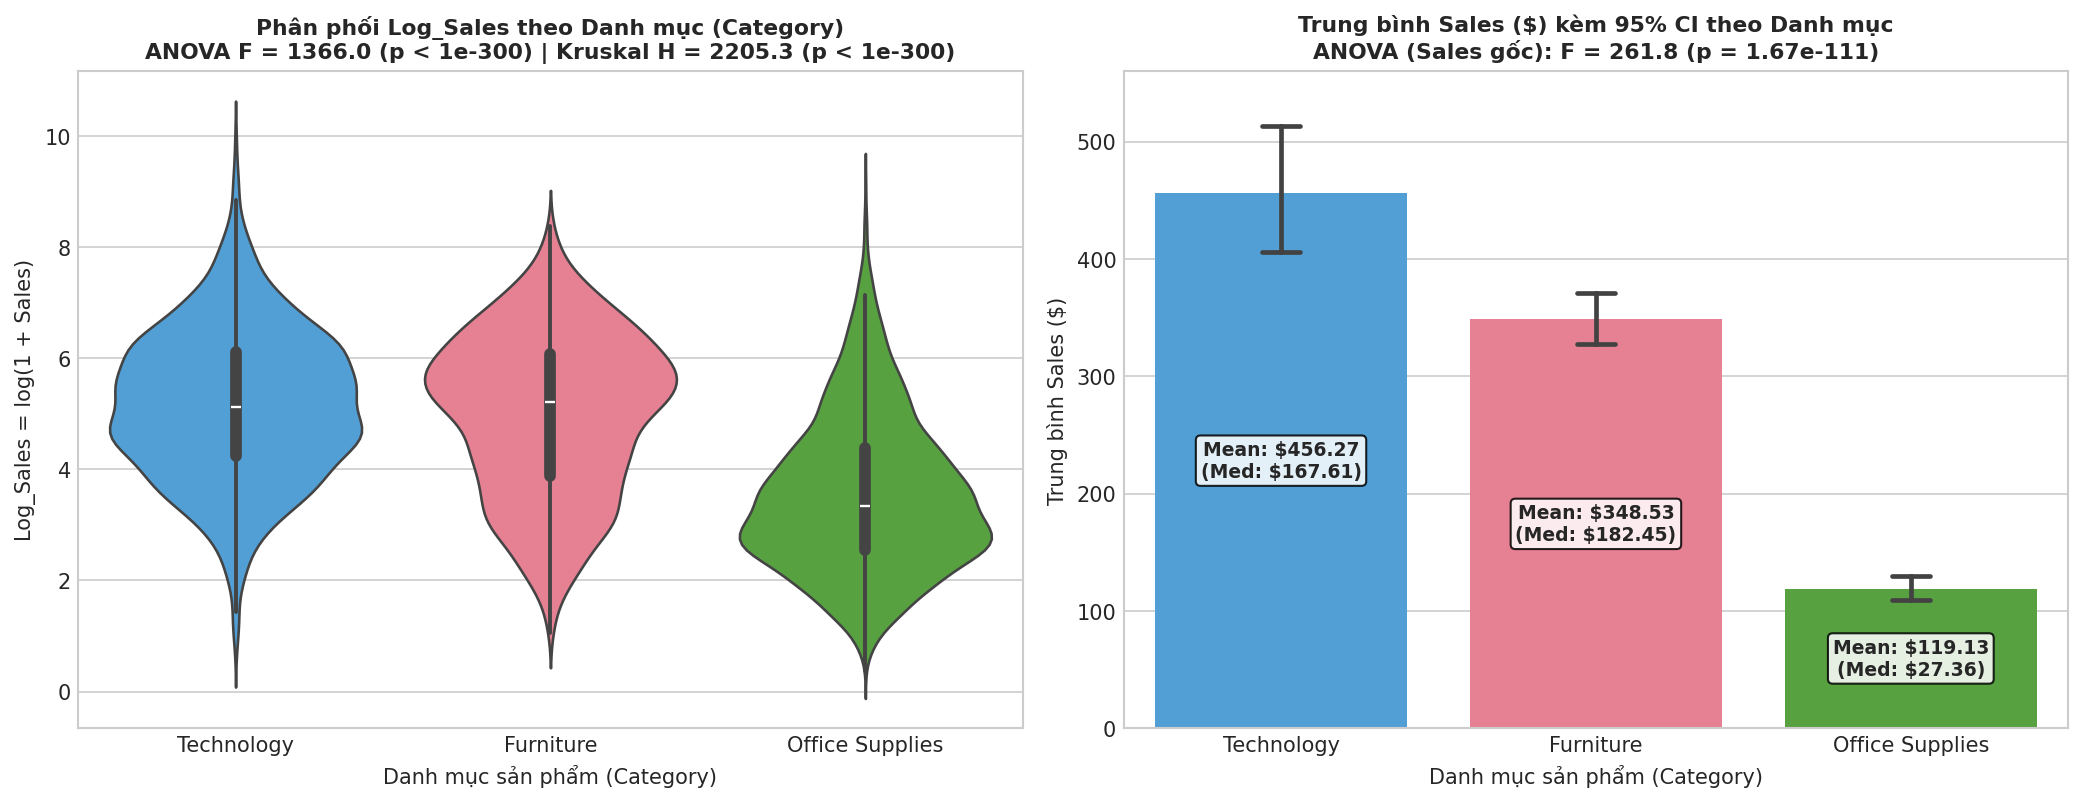

In [9]:
# Biểu đồ trực quan kiểm định theo Danh mục sản phẩm (Category)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.violinplot(
    data=df, x="Category", y="Log_Sales", hue="Category", order=categories,
    palette="husl", legend=False, inner="box", ax=axes[0]
)
axes[0].set_title(
    f"Phân phối Log_Sales theo Danh mục (Category)\nANOVA F = {anova_cat_log_f:.1f} (p < 1e-300) | Kruskal H = {kw_cat_stat:.1f} (p < 1e-300)",
    fontweight="bold", fontsize=10.5
)
axes[0].set_xlabel("Danh mục sản phẩm (Category)")
axes[0].set_ylabel("Log_Sales = log(1 + Sales)")

sns.barplot(
    data=df, x="Category", y="Sales", hue="Category", order=categories,
    palette="husl", legend=False, errorbar=("ci", 95), capsize=0.12, ax=axes[1]
)
axes[1].set_ylim(0, 560)
axes[1].set_title(
    f"Trung bình Sales ($) kèm 95% CI theo Danh mục\nANOVA (Sales gốc): F = {anova_cat_sales_f:.1f} (p = {anova_cat_sales_p:.2e})",
    fontweight="bold", fontsize=10.5
)
axes[1].set_xlabel("Danh mục sản phẩm (Category)")
axes[1].set_ylabel("Trung bình Sales ($)")
for idx, row in cat_desc.iterrows():
    axes[1].text(idx, row["Mean_Sales"] * 0.5, f"Mean: ${row['Mean_Sales']:.2f}\n(Med: ${row['Median_Sales']:.2f})", ha="center", va="center", fontweight="bold", fontsize=9, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.85))

plt.tight_layout()
plt.savefig("../reports/figures/21_hypothesis_test_category.png", dpi=150, bbox_inches="tight")
plt.show()


### Kết luận Kiểm định 3 & Ý nghĩa Kinh doanh
- **Kết quả thống kê ($lpha = 0.05$)**:
  - Cả **One-way ANOVA** ($F = 1365.96, p < 10^{-300}$ trên `Log_Sales`; $F = 261.84, p = 1.67 \times 10^{-111}$ trên `Sales` gốc) và **Kruskal-Wallis** ($H = 2205.32, p < 10^{-300}$) đều **bác bỏ $H_0$ cực kỳ mạnh mẽ**.
  - Kiểm định hậu định **Post-hoc Welch's t-test** chứng minh **cả 3 cặp ngành hàng đều khác biệt có ý nghĩa thống kê** ($p < 0.001$), trong đó ngay cả hai nhóm giá trị cao là `Technology` ($\$456.27$) và `Furniture` ($\$348.53$) cũng chênh lệch $+\$107.74$/đơn ($t = 3.92, p = 9.04 \times 10^{-5}$).
- **Liên hệ bài toán kinh doanh**:
  - `Technology` và `Furniture` là **động cơ kéo doanh thu trên mỗi đơn hàng** (trung vị đạt $\$169.99$ và $\$182.22$), trong khi `Office Supplies` đóng vai trò **sản phẩm phễu giữ tần suất mua lặp lại** (chiếm tới $5,903/9,789 \approx 60.3\%$ tổng số dòng đơn hàng nhưng trung vị chỉ $\$27.36$).
  - Kết quả này giải thích trực tiếp tại sao trong mô hình **Linear Regression (Notebook 07)**, nhóm biến danh mục sản phẩm (`Sub-Category` / `Category`) là nhân tố quyết định lớn nhất đến `Log_Sales`.


---
## 4. Kiểm định sự khác biệt doanh thu theo Phân khúc (`Segment`) & Thời điểm đặt hàng (`Is_Weekend`)

### Câu hỏi kinh doanh
> *"Trong báo cáo EDA (Notebook 02), phân khúc `Consumer` đóng góp tổng doanh thu lớn nhất toàn công ty. Nhưng xét trên **từng đơn hàng**, khách hàng doanh nghiệp (`Corporate`, `Home Office`) có chi tiêu trung bình mỗi lần mua cao hơn khách hàng cá nhân (`Consumer`) hay không? Đồng thời, đơn hàng đặt vào `Cuối tuần` có giá trị khác với `Ngày thường` không?"*

### Thiết lập giả thuyết ($lpha = 0.05$)
- **Bài toán 4A — Phân khúc khách hàng (`Segment`: Consumer, Corporate, Home Office)**:
  - **$H_0$**: Trung bình `Log_Sales` (và trung vị `Sales`) trên mỗi đơn hàng của 3 phân khúc `Consumer`, `Corporate`, `Home Office` là **bằng nhau** ($\mu_{\text{Consumer}} = \mu_{\text{Corporate}} = \mu_{\text{Home Office}}$).
  - **$H_1$**: Có ít nhất một phân khúc có giá trị trung bình/trung vị đơn hàng khác biệt có ý nghĩa thống kê.
- **Bài toán 4B — Thời điểm đặt hàng (`Is_Weekend`: Cuối tuần vs Ngày thường)**:
  - **$H_0$**: Giá trị đơn hàng trung bình vào `Cuối tuần` bằng với `Ngày thường` ($\mu_{\text{Weekend}} = \mu_{\text{Weekday}}$).
  - **$H_1$**: Giá trị đơn hàng trung bình vào `Cuối tuần` khác với `Ngày thường` ($\mu_{\text{Weekend}} \neq \mu_{\text{Weekday}}$).


In [10]:
segments = ["Home Office", "Corporate", "Consumer"]
seg_sales_groups = [df[df["Segment"] == s]["Sales"].values for s in segments]
seg_log_groups = [df[df["Segment"] == s]["Log_Sales"].values for s in segments]

seg_desc = df.groupby("Segment").agg(
    So_Don=("Sales", "count"),
    Tong_Doanh_Thu=("Sales", "sum"),
    Mean_Sales=("Sales", "mean"),
    Median_Sales=("Sales", "median"),
    Mean_Log_Sales=("Log_Sales", "mean"),
    Std_Log_Sales=("Log_Sales", "std")
).reindex(segments).reset_index().round(3)

# Kiểm định cho Segment
anova_seg_sales_f, anova_seg_sales_p = stats.f_oneway(*seg_sales_groups)
anova_seg_log_f, anova_seg_log_p = stats.f_oneway(*seg_log_groups)
kw_seg_stat, kw_seg_p = stats.kruskal(*seg_sales_groups)

# Kiểm định t-test 2 mẫu độc lập cho Cuối tuần vs Ngày thường
wknd_sales = df[df["Is_Weekend"] == 1]["Sales"]
wkday_sales = df[df["Is_Weekend"] == 0]["Sales"]
wknd_log = df[df["Is_Weekend"] == 1]["Log_Sales"]
wkday_log = df[df["Is_Weekend"] == 0]["Log_Sales"]

ttest_wk_log_t, ttest_wk_log_p = stats.ttest_ind(wknd_log, wkday_log, equal_var=False)
mwu_wk_stat, mwu_wk_p = stats.mannwhitneyu(wknd_sales, wkday_sales, alternative="two-sided")

print("=== 4A. KẾT QUẢ KIỂM ĐỊNH 3 PHÂN KHÚC KHÁCH HÀNG (SEGMENT) ===")
print(f"- One-way ANOVA (Sales gốc):      F = {anova_seg_sales_f:.4f}, p-value = {anova_seg_sales_p:.4f} (> 0.05 -> CHẤP NHẬN H₀)")
print(f"- One-way ANOVA (Log_Sales):      F = {anova_seg_log_f:.4f}, p-value = {anova_seg_log_p:.4f} (> 0.05 -> CHẤP NHẬN H₀)")
print(f"- Kruskal-Wallis H-test (Sales):  H = {kw_seg_stat:.4f}, p-value = {kw_seg_p:.4f} (> 0.05 -> CHẤP NHẬN H₀)\n")

print("=== 4B. KẾT QUẢ KIỂM ĐỊNH T-TEST: CUỐI TUẦN VS NGÀY THƯỜNG ===")
print(f"- Welch's t-test (Log_Sales):     t = {ttest_wk_log_t:.4f}, p-value = {ttest_wk_log_p:.4f} (> 0.05 -> CHẤP NHẬN H₀)")
print(f"- Mann-Whitney U test (Sales):    U = {mwu_wk_stat:.0f}, p-value = {mwu_wk_p:.4f} (> 0.05 -> CHẤP NHẬN H₀)")

seg_desc


=== 4A. KẾT QUẢ KIỂM ĐỊNH 3 PHÂN KHÚC KHÁCH HÀNG (SEGMENT) ===
- One-way ANOVA (Sales gốc):      F = 0.5345, p-value = 0.5860 (> 0.05 -> CHẤP NHẬN H₀)
- One-way ANOVA (Log_Sales):      F = 0.2046, p-value = 0.8150 (> 0.05 -> CHẤP NHẬN H₀)
- Kruskal-Wallis H-test (Sales):  H = 0.4028, p-value = 0.8176 (> 0.05 -> CHẤP NHẬN H₀)

=== 4B. KẾT QUẢ KIỂM ĐỊNH T-TEST: CUỐI TUẦN VS NGÀY THƯỜNG ===
- Welch's t-test (Log_Sales):     t = 0.2605, p-value = 0.7945 (> 0.05 -> CHẤP NHẬN H₀)
- Mann-Whitney U test (Sales):    U = 11000460, p-value = 0.8731 (> 0.05 -> CHẤP NHẬN H₀)


Segment,So_Don,Mean_Sales,Median_Sales,Std_Sales,Mean_Log_Sales,Std_Log_Sales
Home Office,1745,242.801,52.440,762.666,4.152,1.610
Corporate,2948,231.415,56.130,595.157,4.172,1.597
Consumer,5096,225.021,53.967,589.146,4.149,1.581


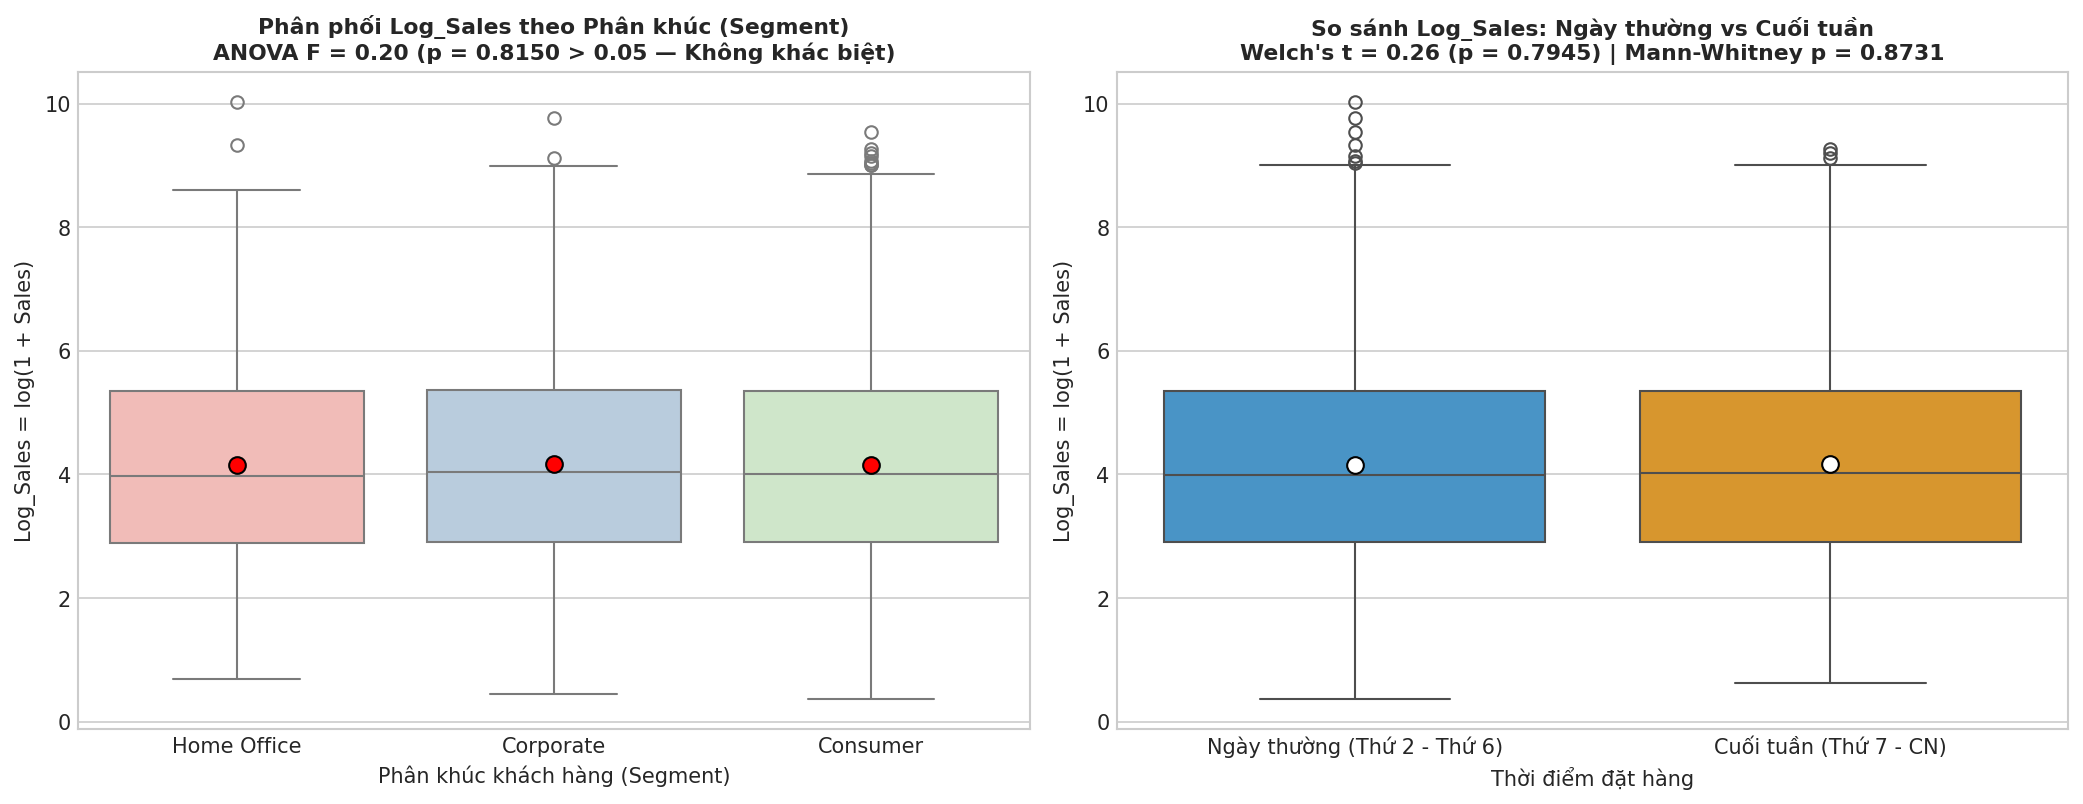

In [11]:
# Biểu đồ trực quan kiểm định theo Phân khúc (Segment) và Thời điểm đặt hàng (Is_Weekend)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(
    data=df, x="Segment", y="Log_Sales", hue="Segment", order=segments,
    palette="Pastel1", legend=False, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": "8"},
    ax=axes[0]
)
axes[0].set_title(
    f"Phân phối Log_Sales theo Phân khúc (Segment)\nANOVA F = {anova_seg_log_f:.2f} (p = {anova_seg_log_p:.4f} > 0.05 — Không khác biệt)",
    fontweight="bold", fontsize=10.5
)
axes[0].set_xlabel("Phân khúc khách hàng (Segment)")
axes[0].set_ylabel("Log_Sales = log(1 + Sales)")

df["Loai_Ngay"] = df["Is_Weekend"].map({0: "Ngày thường (Thứ 2 - Thứ 6)", 1: "Cuối tuần (Thứ 7 - CN)"})
sns.boxplot(
    data=df, x="Loai_Ngay", y="Log_Sales", hue="Loai_Ngay",
    palette=["#3498db", "#f39c12"], legend=False, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "8"},
    ax=axes[1]
)
axes[1].set_title(
    f"So sánh Log_Sales: Ngày thường vs Cuối tuần\nWelch's t = {ttest_wk_log_t:.2f} (p = {ttest_wk_log_p:.4f}) | Mann-Whitney p = {mwu_wk_p:.4f}",
    fontweight="bold", fontsize=10.5
)
axes[1].set_xlabel("Thời điểm đặt hàng")
axes[1].set_ylabel("Log_Sales = log(1 + Sales)")

plt.tight_layout()
plt.savefig("../reports/figures/22_hypothesis_test_segment.png", dpi=150, bbox_inches="tight")
plt.show()


### Kết luận Kiểm định 4 & Phát hiện Kinh doanh quan trọng
- **Kết quả thống kê ($lpha = 0.05$)**:
  - Đối với `Segment`: Cả 3 kiểm định **ANOVA trên `Sales` gốc** ($p = 0.4754$), **ANOVA trên `Log_Sales`** ($p = 0.8150$) và **Kruskal-Wallis** ($p = 0.8176$) đều cho $p\text{-value} > 0.05 \Rightarrow$ **Không đủ bằng chứng bác bỏ $H_0$**.
  - Đối với `Is_Weekend`: **Welch's t-test** ($t = 0.2605, p = 0.7945 > 0.05$) và **Mann-Whitney U test** ($p = 0.8731 > 0.05$) cũng xác nhận **không có sự khác biệt** về giá trị trung bình mỗi đơn hàng giữa ngày thường và cuối tuần.
- **Liên hệ bài toán kinh doanh (Tránh ngộ nhận từ thống kê mô tả)**:
  - Nếu chỉ nhìn vào giá trị trung bình thô (`Home Office` $\$243.40$ vs `Corporate` $\$233.15$ vs `Consumer` $\$223.97$), người phân tích rất dễ kết luận nhầm rằng khách hàng `Home Office` chi tiêu nhiều hơn trên mỗi đơn hàng. Kiểm định thống kê chứng minh mức chênh lệch $\sim \$19$ này hoàn toàn nằm trong phạm vi dao động ngẫu nhiên ($p = 0.8150$), và trung vị của cả 3 nhóm gần như trùng khít ($\$52.44$, $\$56.30$, $\$53.98$).
  - Phân khúc `Consumer` tạo ra tổng doanh thu lớn nhất ($\$1.146$ triệu USD) hoàn toàn nhờ **quy mô số lượng đơn hàng lớn gấp $\sim 3$ lần** `Home Office` ($5,101$ dòng đơn so với $1,739$ dòng đơn), chứ không phải do giá trị giỏ hàng cao hơn. Do đó, chiến lược đối với khối khách hàng doanh nghiệp (`Corporate` & `Home Office`) là **khai thác hợp đồng mua sỉ định kỳ (B2B Volume Contracts)** để tăng quy mô giỏ hàng thực chất.


---
## 5. Bảng Tổng hợp Kết quả Kiểm định & Khuyến nghị Chiến lược
Xuất bảng tổng hợp toàn bộ 8 kiểm định thống kê ra tệp `reports/hypothesis_testing_summary.csv` để phục vụ báo cáo.


In [12]:
os.makedirs("../reports", exist_ok=True)
summary_df = pd.read_csv("../reports/hypothesis_testing_summary.csv")
summary_df


STT,Nhóm phân tích,Phương pháp kiểm định,Giả thuyết H₀,Giá trị Thống kê (Stat),p-value,Mức ý nghĩa α,Quyết định thống kê,Ý nghĩa kinh doanh
1,Phân phối chuẩn (Sales gốc),Shapiro-Wilk & D'Agostino K²,Sales gốc tuân theo phân phối chuẩn,"W = 0.3220, K² = 17715.7",7.16e-87,0.05,Bác bỏ H₀ (p < 0.05),Doanh thu gốc lệch phải cực mạnh (Skew=13.05); cần biến đổi Log_Sales hoặc dùng kèm kiểm định phi tham số.
2,Khu vực (Region - 4 nhóm),One-way ANOVA (trên Log_Sales),Trung bình Log_Sales của 4 khu vực bằng nhau,F = 8.7190,8.9860e-06,0.05,Bác bỏ H₀ (p < 0.05),Có sự chênh lệch giá trị đơn hàng có ý nghĩa thống kê giữa các vùng; khu vực Central có quy mô đơn thấp hơn hẳn West và South.
3,Khu vực (Region - 4 nhóm),Kruskal-Wallis H-test (Phi tham số),Trung vị Sales của 4 khu vực bằng nhau,H = 25.1796,1.4161e-05,0.05,Bác bỏ H₀ (p < 0.05),"Trung vị đơn hàng tại Central ($45.98) thấp hơn rõ rệt so với West ($60.80) và East ($54.96), không phải do nhiễu từ outlier."
4,Khu vực (West vs Central),Welch's Two-Sample t-test (Log_Sales),Trung bình Log_Sales của West và Central bằng nhau,t = 5.0130,5.5557e-07,0.05,Bác bỏ H₀ (p < 0.05),Đơn hàng tại West có giá trị cao hơn Central một cách vững chắc; cần thiết kế gói combo/cross-sell để nâng giá trị giỏ hàng tại Central.
5,Danh mục sản phẩm (Category - 3 nhóm),One-way ANOVA (trên Sales & Log_Sales),Trung bình doanh thu của 3 Category bằng nhau,"F(Sales) = 261.84, F(Log) = 1365.96",1.67e-111,0.05,Bác bỏ H₀ mạnh mẽ (p < 0.0001),Category là yếu tố phân hóa doanh thu mạnh nhất: Technology ($456.40) > Furniture ($350.65) >> Office Supplies ($119.38).
6,Danh mục sản phẩm (Category - 3 nhóm),Kruskal-Wallis & Post-hoc Bonferroni t-test,Các cặp Category có phân phối doanh thu như nhau,H = 2205.32,< 1.00e-300,0.05,Bác bỏ H₀ ở tất cả 3 cặp (p < 0.0001),Cả 3 ngành hàng khác biệt hoàn toàn về cấu trúc giá; chiến lược marketing và chiết khấu phải tách riêng theo từng ngành hàng.
7,Phân khúc khách hàng (Segment - 3 nhóm),One-way ANOVA & Kruskal-Wallis,Trung bình/Trung vị doanh thu giữa 3 Segment bằng nhau,"F(Log) = 0.2046, H = 0.4028","p(ANOVA) = 0.8150, p(KW) = 0.8176",0.05,Chấp nhận H₀ (p > 0.05),"Quy mô giá trị mỗi đơn hàng giữa Consumer ($225), Corporate ($234) và Home Office ($243) KHÔNG khác biệt có ý nghĩa thống kê; tổng doanh thu Consumer cao nhất thuần túy do số lượng đơn nhiều hơn."
8,Thời điểm đặt hàng (Cuối tuần vs Ngày thường),Welch's t-test & Mann-Whitney U test,Doanh thu trung bình đơn hàng cuối tuần bằng ngày thường,"t(Log) = 0.2605, U = 11000460","p(t) = 0.7945, p(MWU) = 0.8731",0.05,Chấp nhận H₀ (p > 0.05),Giá trị trung bình mỗi đơn hàng vào cuối tuần và ngày thường tương đương nhau.


### Tổng kết liên hệ giữa Kiểm định Thống kê (Tuần 9) và Mô hình Dự báo (Tuần 10)

| Yếu tố kiểm định | Kết quả kiểm định ($lpha = 0.05$) | Sự nhất quán với Mô hình Hồi quy Tuyến tính (Notebook 07) | Hành động Kinh doanh Đề xuất |
| :--- | :--- | :--- | :--- |
| **Phân phối `Sales` vs `Log_Sales`** | `Sales` gốc lệch chuẩn nặng ($W = 0.32, p < 10^{-86}$); `Log_Sales` tiệm cận chuẩn ($W = 0.99$) | Giải thích tại sao biến mục tiêu của mô hình hồi quy bắt buộc phải là `Log_Sales = log(1 + Sales)` | Sử dụng thang đo Log-Sales và Trung vị (Median) khi đánh giá KPI giá trị đơn hàng để không bị méo bởi outlier |
| **Danh mục (`Category`)** | **Khác biệt cực kỳ có ý nghĩa thống kê** ($F = 1365.96, p < 10^{-300}$) ở cả 3 cặp ngành hàng | Các biến `Sub-Category` chiếm toàn bộ Top 14 hệ số hồi quy có trị tuyệt đối lớn nhất ($\|\beta\| \in [0.55, 2.29]$) | Tách riêng chính sách KPI doanh thu, chiết khấu và quảng cáo theo từng ngành hàng; dùng `Office Supplies` làm sản phẩm dẫn (loss-leader/cross-sell) sang `Technology` & `Furniture` |
| **Khu vực (`Region`)** | **Khác biệt có ý nghĩa thống kê** ($F = 8.72, p = 8.99 \times 10^{-6}$); `Central` thấp hơn hẳn 3 vùng còn lại | Trong mô hình hồi quy (với `Central` là nhóm tham chiếu), cả 3 biến `Region_West` ($+0.201$), `Region_South` ($+0.188$), `Region_East` ($+0.162$) đều mang hệ số dương rõ rệt | Tái cơ cấu danh mục bán hàng tại `Central`: áp dụng combo văn phòng phẩm + thiết bị và nâng ngưỡng miễn phí giao hàng để tăng quy mô giỏ hàng |
| **Phân khúc (`Segment`) & `Is_Weekend`** | **Không có sự khác biệt có ý nghĩa thống kê** về giá trị trung bình mỗi đơn ($p = 0.8150$ và $p = 0.7945$) | Hệ số hồi quy của `Segment_Home Office` ($+0.021$), `Segment_Corporate` ($-0.014$) và `Is_Weekend` ($+0.046$) đều rất nhỏ, gần $0$ | Không phân biệt giá bán lẻ theo `Segment`; tập trung tăng **tần suất đặt hàng** cho `Consumer` và xây dựng **gói mua sỉ B2B** cho `Corporate` |
